# memeGen demo — meme captioning with CLIP + Transformer
### Loads the best checkpoint (`long_cl?ip_transformer_emb768`, 3 epochs) from the
### GitHub v1.0 release and captions meme templates with a Gradio UI.
### Use a GPU runtime (Runtime ▸ Change runtime type ▸ T4 GPU).

## 1. Install dependencies

In [2]:
!pip -q install -U transformers gradio

## 2. Clone the repo

In [3]:
import os
os.environ["HF_HUB_OFFLINE"] = "0"
os.environ["Transformers"] = "0"
!git clone "https://github.com/MohammeddArsh/memeGen.git"
%cd memeGen

fatal: destination path 'memeGen' already exists and is not an empty directory.
/content/memeGen


In [4]:
!ls

caption.py     encoders.py    model.py	 requirements.txt  showcase.py
check_data.py  eval.py	      NOTES.md	 results	   train.py
data.py        memes900k.zip  README.md  showcase


## 3. Get the data and checkpoint

In [5]:
!unzip -n -q memes900k.zip

In [6]:
!ls memes900k/images | wc -l
!wget https://github.com/MohammeddArsh/memeGen/releases/download/v1.0/best.pt

300
--2026-10-13 21:39:32--  https://github.com/MohammeddArsh/memeGen/releases/download/v1.0/best.pt
Resolving github.com (github.com)... 140.82.114.4
Connecting to github.com (github.com)|140.82.114.4|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://release-assets.githubusercontent.com/github-production-release-asset/1397592923/86fd7788-a1d7-4695-9d7f-1a8c12ccfccb?sp=r&sv=2018-11-09&sr=b&spr=https&se=2026-10-13T22%3A34%3A20Z&rscd=attachment%3B+filename%3Dbest.pt&rsct=application%2Foctet-stream&skoid=96c2d410-5711-43a1-aedd-ab1947aa7ab0&sktid=398a6654-997b-47e9-b12b-9515b896b4de&skt=2026-10-13T21%3A33%3A57Z&ske=2026-10-13T22%3A34%3A20Z&sks=b&skv=2018-11-09&sig=b1Sb1aqL1kWKG%2BJkjd78IKg81pMeJWUrIGqtc5kQLrE%3D&jwt=eyJ0eXAiOiJKV1QiLCJhbGciOiJIUzI1NiJ9.eyJpc3MiOiJnaXRodWIuY29tIiwiYXVkIjoicmVsZWFzZS1hc3NldHMuZ2l0aHVidXNlcmNvbnRlbnQuY29tIiwia2V5Ijoia2V5MSIsImV4cCI6MTc5MTkzMTE3MywibmJmIjoxNzkxOTI3NTczLCJwYXRoIjoicmVsZWFzZWFzc2V0cHJvZHVjdGlvbi5ibG9iLmNvcmU

## 4. Impact font for the overlay

In [7]:
import shutil
for src in ["/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf",
            "/usr/share/fonts/truetype/liberation/LiberationSans-Bold.ttf"]:
  if os.path.exists(src):
    shutil.copy(src, "impact.ttf")
    break

## 5. Imports

In [8]:
import torch
from PIL import Image
import data, caption
from encoders import build_encoder, ENCODER_DIMS
from model import build_model, generate

In [10]:
!ls data.py encoders.py model.py

data.py  encoders.py  model.py


## 6. Load the checkpoint and model

In [11]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

In [12]:
tok = data.build_tokenizer()

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

In [13]:
ckpt = torch.load("best.pt", map_location="cpu", weights_only=False)

In [14]:
cfg = ckpt["args"]

In [15]:
model = build_model(
    cfg["decoder"],                 # "transformer"
    len(tok),
    data.PAD_ID,
    ENCODER_DIMS[cfg["encoder"]],
    cfg,
)

In [16]:
model.load_state_dict(ckpt["model"])
model.eval()
model.to(DEVICE)

TransformerCaptionModel(
  (token_emb): Embedding(50261, 768, padding_idx=50260)
  (pos_emb): Embedding(64, 768)
  (img_proj): Linear(in_features=768, out_features=768, bias=True)
  (decoder): TransformerDecoder(
    (layers): ModuleList(
      (0-5): 6 x TransformerDecoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
        )
        (multihead_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
        )
        (linear1): Linear(in_features=768, out_features=2048, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=2048, out_features=768, bias=True)
        (norm1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm3): LayerNorm((768,), eps=1e-05, element

In [17]:
tfm, fwd, _ = build_encoder(cfg["encoder"], DEVICE)

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] CLIPVisionModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.self_attn.k_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.out_proj.bias   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.final_layer_norm.weight        

In [18]:
print(DEVICE, "| params (M):", round(sum(p.numel() for p in model.parameters())/1e6, 1))

cpu | params (M): 86.5


## 7. Caption + overlay helpers

In [23]:
import re
def _clean(s):
  return re.sub(r"\s*<emp>\s*", " ", s).strip()

@torch.no_grad()
def caption_image(img, strategy="sample", temperature=0.9, top_k=50, seed=None):
  x = tfm(img.convert("RGB")).unsqueeze(0).to(DEVICE)
  feat = fwd(x)
  top, bottom = generate(model, feat, tok,
                       max_new=cfg["max_length"],
                       strategy=strategy,
                       temperature=temperature,
                       top_k=top_k,
                       device=DEVICE, seed=seed)
  return _clean(top), _clean(bottom)

In [24]:
def to_meme(img, top, bottom, tmp="_in.png"):
    img.convert("RGB").save(tmp)
    return caption.render_captioned(tmp, top, bottom)

## 8. Sanity check

TOP:    back in my day
BOTTOM: we used to be a sir


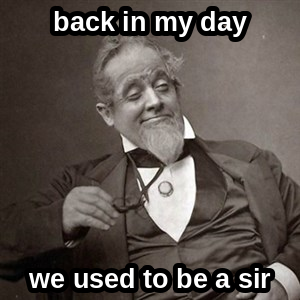

In [26]:
imgs = data.list_images()
img = Image.open(f"memes900k/images/{imgs[0]}")
top, bottom = caption_image(img, strategy="greedy", seed=0)
print("TOP:   ", top)
print("BOTTOM:", bottom)
to_meme(img, top, bottom)

## 9. Gradio UI

In [30]:
import gradio as gr

def demo(img, strategy, temp, n):
    if img is None:
        return []
    return [to_meme(img, *(caption_image(img, strategy=strategy, temperature=temp)))
            for _ in range(int(n))]

In [35]:
with gr.Blocks() as ui:
              gr.Markdown("## memeGen demo — CLIP ViT-B/32 + Transformer (3 epochs)")

              img_in = gr.Image(type="pil", label="Upload a template")
              tmpl   = gr.Dropdown(data.list_images(), label="…or pick a memes900k template")

              with gr.Row():
                  strategy = gr.Radio(["sample", "greedy"], value="sample", label="Decoding")
                  temp     = gr.Slider(0.5, 1.5, value=0.9, step=0.05, label="Temperature")
                  n        = gr.Slider(1, 6, value=3, step=1, label="Variants")

              btn  = gr.Button("Caption", variant="primary")
              gal  = gr.Gallery(columns=3, label="Generated memes")
              tmpl.change(lambda f: Image.open(f"memes900k/images/{f}"), tmpl, img_in)
              btn.click(demo, inputs=[img_in, strategy, temp, n], outputs=gal)
              ui.launch(debug=True, share=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://406eacce21c9c6d650.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://406eacce21c9c6d650.gradio.live
